# VQA v2 Top-1,000 三组对齐对照实验

本 Notebook 对比三种训练方案，**每组都从随机初始化的分类头开始训练同样的轮次**，
训练预算、数据划分、随机种子与超参完全对齐，因此差异只来自"是否使用图像"和
"是否微调视觉编码器"这两个变量。

| 组 | 图像输入 | 视觉编码器 | 分类头 |
| --- | --- | --- | --- |
| `text` | 无 | 文本编码器冻结 | 随机初始化后训练 |
| `fusion` | 有 | 视觉编码器**冻结** | 随机初始化后训练 |
| `finetune` | 有 | 视觉编码器**末层解冻** | 随机初始化后训练 |

与历史 pilot 的区别：历史版本让冻结组与微调组从"已训好的冻结模型"续训 2 轮，
轮次与超参不一致，无法干净归因。本实验三组各自从头训练 `EPOCHS` 轮。

数据：https://visualqa.org/download ；图片：https://cocodataset.org/ ；
模型与实现：https://github.com/openai/CLIP 。请在使用数据和预训练权重时遵守各自许可。


In [ ]:
from __future__ import annotations

import copy
import hashlib
import json
import math
import os
import platform
import re
import sys
import time
from collections import Counter
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Dataset, TensorDataset


cwd = Path.cwd()
ROOT = next((path for path in (cwd, *cwd.parents, cwd / "vqa_project")
             if (path / "scripts" / "prepare_data.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open the notebook from the VQA repository")
os.chdir(ROOT)

DATA = Path(os.environ.get("VQA_DATA_ROOT", ROOT / "data")).expanduser().resolve()
VENDOR = Path(os.environ.get("VQA_VENDOR_ROOT", ROOT / "vendor")).expanduser().resolve()
sys.path[:0] = [str(VENDOR), str(VENDOR / "CLIP-main"), str(ROOT / "scripts")]
import clip
from prepare_data import joined_rows


SEED = 42
EPOCHS = 10
BATCH_SIZE = 32
HEAD_LR = 8e-4
BACKBONE_LR = 1e-5
WEIGHT_DECAY = 0.01
FEATURE_SCALE = math.sqrt(512)
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
RESULTS = ROOT / "results"
if not RESULTS.is_dir():
    RESULTS.mkdir(parents=True)

torch.manual_seed(SEED)
random_seed_state = torch.random.get_rng_state()

print(f"device: {DEVICE}")
if DEVICE == "mps":
    print("note: Apple MPS backend; results are not comparable with the CUDA run on another machine.")


## 1 数据划分与词表覆盖率

训练集与开发集按官方 train/val 图片隔离。开发集 800 张图按图片 ID 再分成
600 张模型选择图片和 200 张置信度校准图片；校准集不参与模型选择。
题型标注只用于结果分组，不用来限制模型输出。


In [ ]:
train_manifest_path = DATA / "manifest_top1000.json"
dev_manifest_path = DATA / "manifest_top1000_dev.json"
train_manifest = json.loads(train_manifest_path.read_text(encoding="utf-8"))
dev_manifest = json.loads(dev_manifest_path.read_text(encoding="utf-8"))
vocabulary = train_manifest["vocabulary"]
answer_to_id = {answer: i for i, answer in enumerate(vocabulary)}
train_rows = train_manifest["rows"]
dev_rows = dev_manifest["rows"]
train_ids = {row["image_id"] for row in train_rows}
dev_ids = sorted({row["image_id"] for row in dev_rows})

val_rows = joined_rows("val")
all_dev = [row for row in val_rows if row["image_id"] in set(dev_ids)]
for row in all_dev:
    row["label_id"] = answer_to_id.get(row["answer"], -1)
assert {row["question_id"] for row in dev_rows} <= {row["question_id"] for row in all_dev}
coverage = len(dev_rows) / len(all_dev)

rng = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(dev_ids), generator=rng).tolist()
selection_ids = {dev_ids[i] for i in perm[:600]}
calibration_ids = {dev_ids[i] for i in perm[600:800]}

selection_rows = [r for r in dev_rows if r["image_id"] in selection_ids]
calibration_rows = [r for r in dev_rows if r["image_id"] in calibration_ids]
seen_train_labels = {row["label_id"] for row in train_rows}
unseen_dev_questions = sum(row["label_id"] not in seen_train_labels for row in dev_rows)

print(f"Train: {len(train_rows)} QA / {len(train_ids)} images")
print(f"Dev: {len(dev_rows)} in-vocab QA / {len(all_dev)} total QA / "
      f"{len(dev_ids)} images; coverage={coverage:.1%}")
print(f"Model selection: {len(selection_rows)} QA; calibration: {len(calibration_rows)} QA")
print(f"Training labels observed: {len(seen_train_labels)}/1000; "
      f"in-vocabulary dev QA with unseen training label: {unseen_dev_questions}")
print("Unfiltered dev answer types:", dict(Counter(r["answer_type"] for r in all_dev)))


## 2 冻结 CLIP 编码器并缓存文本与图像特征

问题和图片各编码成 512 维全局向量。图文输入为 `[q,v,q*v,|q-v|]`；
仅文本输入为 `[q,0,0,0]`。特征归一化后乘以 √512。

微调组不能使用缓存的图像特征，因为它需要梯度流过视觉编码器；
该组在训练时实时编码图片。


In [ ]:
weight_path = DATA / "raw" / "ViT-B-32.pt"
expected_sha = "40d365715913c9da98579312b702a82c18be219cc2a73407c4526f58eba950af"
assert hashlib.sha256(weight_path.read_bytes()).hexdigest() == expected_sha
clip_model, preprocess = clip.load(str(weight_path), device=DEVICE, jit=False)
clip_model = clip_model.float().eval()
for parameter in clip_model.parameters():
    parameter.requires_grad_(False)

class ImageDataset(Dataset):
    def __init__(self, paths):
        self.paths = paths
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, index):
        path = self.paths[index]
        with Image.open(DATA / "images" / path) as image:
            pixels = preprocess(image.convert("RGB"))
        return path, pixels

cache_hash = hashlib.sha256(train_manifest_path.read_bytes() +
                            dev_manifest_path.read_bytes() + expected_sha.encode()).hexdigest()[:12]
cache_path = RESULTS / f"top1000_features_{cache_hash}.pt"
if cache_path.is_file():
    features = torch.load(cache_path, map_location="cpu", weights_only=True)
else:
    image_paths = sorted({row["image"] for row in train_rows} |
                         {row["image"] for row in all_dev})
    image_features = {}
    loader = DataLoader(ImageDataset(image_paths), batch_size=64, shuffle=False, num_workers=0)
    start = time.perf_counter()
    with torch.inference_mode():
        for names, pixels in loader:
            encoded = (F.normalize(clip_model.encode_image(pixels.to(DEVICE)).float(), dim=-1)
                       * FEATURE_SCALE).cpu()
            for name, vector in zip(names, encoded):
                image_features[name] = vector
    print(f"Encoded {len(image_features)} unique images in {time.perf_counter()-start:.1f}s")

    question_features = {}
    start = time.perf_counter()
    with torch.inference_mode():
        for offset in range(0, len(train_rows) + len(all_dev), 128):
            group = (train_rows + all_dev)[offset:offset + 128]
            tokens = clip.tokenize([row["question"] for row in group], truncate=True).to(DEVICE)
            encoded = (F.normalize(clip_model.encode_text(tokens).float(), dim=-1)
                       * FEATURE_SCALE).cpu()
            for row, vector in zip(group, encoded):
                question_features[row["question_id"]] = vector
    print(f"Encoded {len(question_features)} questions in {time.perf_counter()-start:.1f}s")
    features = {"images": image_features, "questions": question_features}
    torch.save(features, cache_path)
print("Feature cache:", cache_path.name)

def fuse(question_vector, image_vector):
    return torch.cat((question_vector, image_vector,
                      question_vector * image_vector,
                      (question_vector - image_vector).abs()), dim=-1)

def cached_vectors(rows, mode):
    result = []
    for row in rows:
        q = features["questions"][row["question_id"]]
        if mode == "text":
            z = torch.zeros_like(q)
            result.append(torch.cat((q, z, z, z), dim=-1))
        else:
            v = features["images"][row["image"]]
            result.append(fuse(q, v))
    return torch.stack(result)


## 3 三组对齐训练

三组都从随机初始化的分类头开始，训练 `EPOCHS` 轮，损失、优化器、batch size、
学习率、随机种子一致。分类头的初始权重在每组之前被重置为同一份，
因此"仅文本"与"图文融合"的差别只来自输入中有没有图像向量。

微调组额外解冻 CLIP 视觉 Transformer 的最后一个 block、`ln_post` 与投影层，
视觉编码器使用更小的学习率（`BACKBONE_LR`），其余参数保持冻结。


In [ ]:
class AnswerHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2048, 512), nn.ReLU(),
                                 nn.Dropout(0.2), nn.Linear(512, len(vocabulary)))
    def forward(self, x):
        return self.net(x)

def logits_for(head, x):
    head.eval()
    with torch.inference_mode():
        return torch.cat([head(batch.to(DEVICE)).cpu() for batch in x.split(512)])

def head_init_state():
    """Return a fresh classification-head initialisation shared by all groups."""
    torch.manual_seed(SEED + 11)
    return copy.deepcopy(AnswerHead().state_dict())

# ---- 视觉主干缓存（仅微调组使用）----
# 微调组只解冻最后一个 Transformer block、ln_post 和 proj，前面 11 个 block 全程冻结，
# 因此它们的输出在每个 epoch 上完全相同。把冻结部分预先算一次并缓存，训练时每批只剩
# 一个 block 的前向与反向。数学上与整模型前向等价，只改变计算顺序。
def split_visual(visual):
    """Split the 12 ViT blocks into the frozen trunk and the single trainable tail block."""
    blocks = list(visual.transformer.resblocks)
    return blocks[:-1], blocks[-1]


def run_frozen_trunk(visual, frozen_blocks, pixels_batch):
    """Reproduce VisionTransformer.forward up to (not including) the last block."""
    x = visual.conv1(pixels_batch)
    x = x.reshape(x.shape[0], x.shape[1], -1).permute(0, 2, 1)
    x = torch.cat([
        visual.class_embedding.to(x.dtype)
        + torch.zeros(x.shape[0], 1, x.shape[-1], dtype=x.dtype, device=x.device), x,
    ], dim=1)
    x = x + visual.positional_embedding.to(x.dtype)
    x = visual.ln_pre(x)
    x = x.permute(1, 0, 2)
    for block in frozen_blocks:
        x = block(x)
    return x


def run_trainable_tail(visual, tail_block, trunk_state):
    """Reproduce VisionTransformer.forward from the last block onward."""
    x = tail_block(trunk_state)
    x = x.permute(1, 0, 2)
    x = visual.ln_post(x[:, 0, :])
    if visual.proj is not None:
        x = x @ visual.proj
    return x


def build_trunk_cache(visual, frozen_blocks, image_names, chunk=64):
    """Decode each image once and cache the frozen trunk's output: (tokens, 1, width) per image."""
    cache = {}
    for start in range(0, len(image_names), chunk):
        group = image_names[start:start + chunk]
        batch = torch.stack([
            preprocess(Image.open(DATA / "images" / name).convert("RGB")) for name in group
        ]).to(DEVICE)
        states = run_frozen_trunk(visual, frozen_blocks, batch).cpu()
        for offset, name in enumerate(group):
            cache[name] = states[:, offset:offset + 1, :]
    return cache

def train_cached_group(mode, epochs):
    """Train the text-only or frozen-fusion group on cached features."""
    torch.random.set_rng_state(random_seed_state)
    head = AnswerHead().to(DEVICE)
    head.load_state_dict(head_init_state())
    optimizer = torch.optim.AdamW(head.parameters(), lr=HEAD_LR, weight_decay=WEIGHT_DECAY)
    x_train = cached_vectors(train_rows, mode)
    y_train = torch.tensor([r["label_id"] for r in train_rows], dtype=torch.long)
    x_select = cached_vectors(selection_rows, mode)
    y_select = torch.tensor([r["label_id"] for r in selection_rows], dtype=torch.long)
    loader = DataLoader(TensorDataset(x_train, y_train), batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
    history = []
    best_accuracy, best_epoch, best_state = -1.0, 0, None
    for epoch in range(1, epochs + 1):
        head.train()
        total_loss = 0.0
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(head(x), y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(y)
        accuracy = (logits_for(head, x_select).argmax(1) == y_select).float().mean().item()
        history.append({"epoch": epoch, "train_loss": total_loss / len(y_train),
                        "selection_accuracy": accuracy})
        if accuracy > best_accuracy:
            best_accuracy, best_epoch = accuracy, epoch
            best_state = copy.deepcopy(head.state_dict())
        print(f"{mode:9s} epoch={epoch} loss={history[-1]['train_loss']:.4f} "
              f"selection_acc={accuracy:.3f}", flush=True)
    head.load_state_dict(best_state)
    return head, history, best_epoch, best_accuracy

def train_finetune_group(epochs):
    """Train the group that also updates the last visual block of CLIP."""
    torch.random.set_rng_state(random_seed_state)
    visual = clip_model.visual
    for parameter in visual.parameters():
        parameter.requires_grad_(False)
    frozen_blocks, tail_block = split_visual(visual)
    for parameter in tail_block.parameters():
        parameter.requires_grad_(True)
    for parameter in visual.ln_post.parameters():
        parameter.requires_grad_(True)
    visual.proj.requires_grad_(True)

    head = AnswerHead().to(DEVICE)
    head.load_state_dict(head_init_state())
    optimizer = torch.optim.AdamW([
        {"params": [p for p in visual.parameters() if p.requires_grad], "lr": BACKBONE_LR},
        {"params": head.parameters(), "lr": HEAD_LR},
    ], weight_decay=WEIGHT_DECAY)

    # 冻结主干只算一次：每张图解码一次，前 11 个 block 跑一次，之后 10 个 epoch 全部复用。
    cache_start = time.perf_counter()
    visual.eval()
    image_names = sorted({row["image"] for row in train_rows + selection_rows})
    trunk_cache = build_trunk_cache(visual, frozen_blocks, image_names)
    with torch.inference_mode():
        probe = torch.stack([
            preprocess(Image.open(DATA / "images" / image_names[0]).convert("RGB"))]).to(DEVICE)
        reference = visual(probe)
        split_value = run_trainable_tail(
            visual, tail_block, run_frozen_trunk(visual, frozen_blocks, probe))
        gap = (reference - split_value).abs().max().item()
    print(f"finetune cache: {len(trunk_cache)} images in "
          f"{time.perf_counter() - cache_start:.0f}s; split-forward max |diff| = {gap:.2e}",
          flush=True)
    assert gap < 1e-4, "split forward pass does not match the full model"

    y_select = torch.tensor([r["label_id"] for r in selection_rows], dtype=torch.long)
    select_questions = [features["questions"][r["question_id"]] for r in selection_rows]
    select_trunk = [trunk_cache[r["image"]] for r in selection_rows]
    shuffle = torch.Generator().manual_seed(SEED)
    history = []
    best_accuracy, best_epoch, best_state = -1.0, 0, None
    for epoch in range(1, epochs + 1):
        visual.train()
        head.train()
        total_loss = 0.0
        start = time.perf_counter()
        order = torch.randperm(len(train_rows), generator=shuffle).tolist()
        for offset in range(0, len(order), BATCH_SIZE):
            batch_rows = [train_rows[i] for i in order[offset:offset + BATCH_SIZE]]
            trunk = torch.cat([trunk_cache[r["image"]] for r in batch_rows], dim=1).to(DEVICE)
            q = torch.stack([features["questions"][r["question_id"]] for r in batch_rows]).to(DEVICE)
            y = torch.tensor([r["label_id"] for r in batch_rows], dtype=torch.long, device=DEVICE)
            optimizer.zero_grad(set_to_none=True)
            v = F.normalize(run_trainable_tail(visual, tail_block, trunk).float(), dim=-1) * FEATURE_SCALE
            loss = F.cross_entropy(head(fuse(q, v)), y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(y)
        visual.eval()
        head.eval()
        with torch.inference_mode():
            select_logits = []
            for offset in range(0, len(selection_rows), BATCH_SIZE):
                trunk = torch.cat(select_trunk[offset:offset + BATCH_SIZE], dim=1).to(DEVICE)
                q = torch.stack(select_questions[offset:offset + BATCH_SIZE]).to(DEVICE)
                v = F.normalize(run_trainable_tail(visual, tail_block, trunk).float(),
                                dim=-1) * FEATURE_SCALE
                select_logits.append(head(fuse(q, v)).cpu())
            accuracy = (torch.cat(select_logits).argmax(1) == y_select).float().mean().item()
        history.append({"epoch": epoch, "train_loss": total_loss / len(train_rows),
                        "selection_accuracy": accuracy, "seconds": time.perf_counter() - start})
        if accuracy > best_accuracy:
            best_accuracy, best_epoch = accuracy, epoch
            best_state = copy.deepcopy(head.state_dict())
        print(f"{'finetune':9s} epoch={epoch} loss={history[-1]['train_loss']:.4f} "
              f"selection_acc={accuracy:.3f} {history[-1]['seconds']:.0f}s", flush=True)
    head.load_state_dict(best_state)
    return head, history, best_epoch, best_accuracy


checkpoint_path = RESULTS / "three_way_checkpoint.pt"
reuse = checkpoint_path.is_file() and os.environ.get("THREE_WAY_REUSE", "") == "1"
if reuse:
    # 复用已训练的权重，只重跑评估阶段
    saved = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
    text_head = AnswerHead().to(DEVICE); text_head.load_state_dict(saved["heads"]["text"])
    fusion_head = AnswerHead().to(DEVICE); fusion_head.load_state_dict(saved["heads"]["fusion"])
    finetune_head = AnswerHead().to(DEVICE); finetune_head.load_state_dict(saved["heads"]["finetune"])
    visual = clip_model.visual
    for name, value in saved["visual_delta"].items():
        dict(visual.named_parameters())[name].data.copy_(value.to(DEVICE))
    text_history = saved["histories"]["text"]
    fusion_history = saved["histories"]["fusion"]
    finetune_history = saved["histories"]["finetune"]
    text_epoch = saved["best_epochs"]["text"]
    fusion_epoch = saved["best_epochs"]["fusion"]
    finetune_epoch = saved["best_epochs"]["finetune"]
    text_selection = saved["selection_scores"]["text"]
    fusion_selection = saved["selection_scores"]["fusion"]
    finetune_selection = saved["selection_scores"]["finetune"]
    print("Reused trained groups from", checkpoint_path.name)
else:
    text_head, text_history, text_epoch, text_selection = train_cached_group("text", EPOCHS)
    fusion_head, fusion_history, fusion_epoch, fusion_selection = train_cached_group("fusion", EPOCHS)
    finetune_head, finetune_history, finetune_epoch, finetune_selection = train_finetune_group(EPOCHS)
    # 保存三组权重与训练历史，便于后续只重跑评估阶段
    torch.save({
        "heads": {mode: head.state_dict() for mode, head in
                  (("text", text_head), ("fusion", fusion_head), ("finetune", finetune_head))},
        "histories": {"text": text_history, "fusion": fusion_history, "finetune": finetune_history},
        "best_epochs": {"text": text_epoch, "fusion": fusion_epoch, "finetune": finetune_epoch},
        "selection_scores": {"text": text_selection, "fusion": fusion_selection,
                              "finetune": finetune_selection},
        "visual_delta": {name: p.detach().cpu().clone()
                         for name, p in clip_model.visual.named_parameters()
                         if p.requires_grad},
    }, checkpoint_path)

heads = {"text": text_head, "fusion": fusion_head, "finetune": finetune_head}
histories = {"text": text_history, "fusion": fusion_history, "finetune": finetune_history}
best_epochs = {"text": text_epoch, "fusion": fusion_epoch, "finetune": finetune_epoch}
selection_scores = {"text": text_selection, "fusion": fusion_selection, "finetune": finetune_selection}
selected = max(selection_scores, key=selection_scores.get)
print(f"Selected {selected} using selection accuracy; " +
      ", ".join(f"{k}={v:.3f}" for k, v in selection_scores.items()))

# 还原冻结状态，避免影响后续评估
for parameter in clip_model.visual.parameters():
    parameter.requires_grad_(False)


## 4 开发集评价与置信度校准

同时报告词表内子集和同一批图片上的全部题。VQA-style 分数采用 10 个人工
答案、每次排除一位标注者后计算 min(匹配人数/3, 1)，并做短答案规范化；
官方 Test-Dev 仍须提交 EvalAI 取得最终 VQA Accuracy。
温度参数只用独立的 200 张校准图片拟合。


In [ ]:
def normalize_answer(answer):
    answer = answer.lower().strip().replace("\n", " ").replace("\t", " ")
    answer = re.sub(r"(?<=\d),(?=\d)", "", answer)
    answer = re.sub(r"(?<!\d)\.|\.(?!\d)", " ", answer)
    answer = re.sub(r"[^\w\s':.]", " ", answer)
    words = answer.split()
    numbers = {"none": "0", "zero": "0", "one": "1", "two": "2", "three": "3",
               "four": "4", "five": "5", "six": "6", "seven": "7", "eight": "8",
               "nine": "9", "ten": "10"}
    contractions = {"dont": "don't", "cant": "can't", "wont": "won't",
                    "isnt": "isn't", "arent": "aren't", "doesnt": "doesn't"}
    return " ".join(contractions.get(numbers.get(w, w), numbers.get(w, w))
                    for w in words if w not in {"a", "an", "the"})

def vqa_style_score(prediction, answers):
    prediction = normalize_answer(prediction)
    ground_truth = [normalize_answer(answer) for answer in answers]
    return sum(min(1.0, sum(prediction == answer for j, answer in enumerate(ground_truth)
                            if j != i) / 3.0) for i in range(len(ground_truth))) / len(ground_truth)

def fit_temperature(logits, labels):
    logits = logits.to(DEVICE)
    labels = labels.to(DEVICE)
    log_temp = nn.Parameter(torch.zeros((), device=DEVICE))
    optimizer = torch.optim.LBFGS([log_temp], lr=0.1, max_iter=45)
    def closure():
        optimizer.zero_grad()
        loss = F.cross_entropy(logits / log_temp.exp(), labels)
        loss.backward()
        return loss
    optimizer.step(closure)
    return float(log_temp.detach().exp().clamp(0.05, 20.0))

def score_rows(logits, rows):
    prediction_ids = logits.argmax(1).tolist()
    exact = sum(i == row["label_id"] for i, row in zip(prediction_ids, rows)) / len(rows)
    soft = sum(vqa_style_score(vocabulary[i], row["human_answers"])
               for i, row in zip(prediction_ids, rows)) / len(rows)
    return {"exact_match": exact, "vqa_style": soft, "questions": len(rows)}

def live_logits_for_rows(mode, rows):
    """Evaluate a group on given rows, encoding images live."""
    visual = clip_model.visual
    head = heads[mode]
    visual.eval()
    head.eval()
    output = []
    with torch.inference_mode():
        for offset in range(0, len(rows), BATCH_SIZE):
            group = rows[offset:offset + BATCH_SIZE]
            q = torch.stack([features["questions"][r["question_id"]] for r in group]).to(DEVICE)
            if mode == "text":
                z = torch.zeros_like(q)
                x = torch.cat((q, z, z, z), dim=-1)
            else:
                pixels = torch.stack([
                    preprocess(Image.open(DATA / "images" / r["image"]).convert("RGB"))
                    for r in group]).to(DEVICE)
                v = F.normalize(visual(pixels).float(), dim=-1) * FEATURE_SCALE
                x = fuse(q, v)
            output.append(head(x).cpu())
    return torch.cat(output)

evaluation = {}
all_logits = {}
temperatures = {}
for mode, head in heads.items():
    if mode == "finetune":
        select_logits = live_logits_for_rows("finetune", selection_rows)
        calib_logits = live_logits_for_rows("finetune", calibration_rows)
        all_logits[mode] = live_logits_for_rows("finetune", all_dev)
    else:
        select_logits = logits_for(head, cached_vectors(selection_rows, mode))
        calib_logits = logits_for(head, cached_vectors(calibration_rows, mode))
        all_logits[mode] = logits_for(head, cached_vectors(all_dev, mode))
    calibration_labels = torch.tensor([r["label_id"] for r in calibration_rows])
    temperatures[mode] = fit_temperature(calib_logits, calibration_labels)
    filtered_indices = [i for i, r in enumerate(all_dev) if r["label_id"] >= 0]
    filtered_logits = all_logits[mode][filtered_indices]
    filtered_rows = [all_dev[i] for i in filtered_indices]
    evaluation[mode] = {
        "selection": score_rows(select_logits, selection_rows),
        "calibration": score_rows(calib_logits, calibration_rows),
        "filtered_dev": score_rows(filtered_logits, filtered_rows),
        "unfiltered_dev": score_rows(all_logits[mode], all_dev),
    }
    print(mode, "filtered_dev", evaluation[mode]["filtered_dev"],
          "unfiltered_dev", evaluation[mode]["unfiltered_dev"],
          "temperature", round(temperatures[mode], 3))


majority_answer = Counter(r["answer"] for r in train_rows).most_common(1)[0][0]
majority_logits = torch.full((len(all_dev), len(vocabulary)), -1.0)
majority_logits[:, answer_to_id[majority_answer]] = 1.0
evaluation["majority"] = {"unfiltered_dev": score_rows(majority_logits, all_dev)}

by_type = {}
for answer_type in ("yes/no", "number", "other"):
    indices = [i for i, row in enumerate(all_dev) if row["answer_type"] == answer_type]
    by_type[answer_type] = {
        mode: score_rows(logits[indices], [all_dev[i] for i in indices])
        for mode, logits in all_logits.items()
    }
print("Selected model by answer type:", by_type)


## 5 曲线、结果文件与 HTML 展示数据

页面只展示真实开发集预测。图像从 COCO 官方地址加载，仓库不附带图片。
分数是经独立校准图片拟合的温度缩放 softmax；它仍受词表封闭和抽样偏差限制。


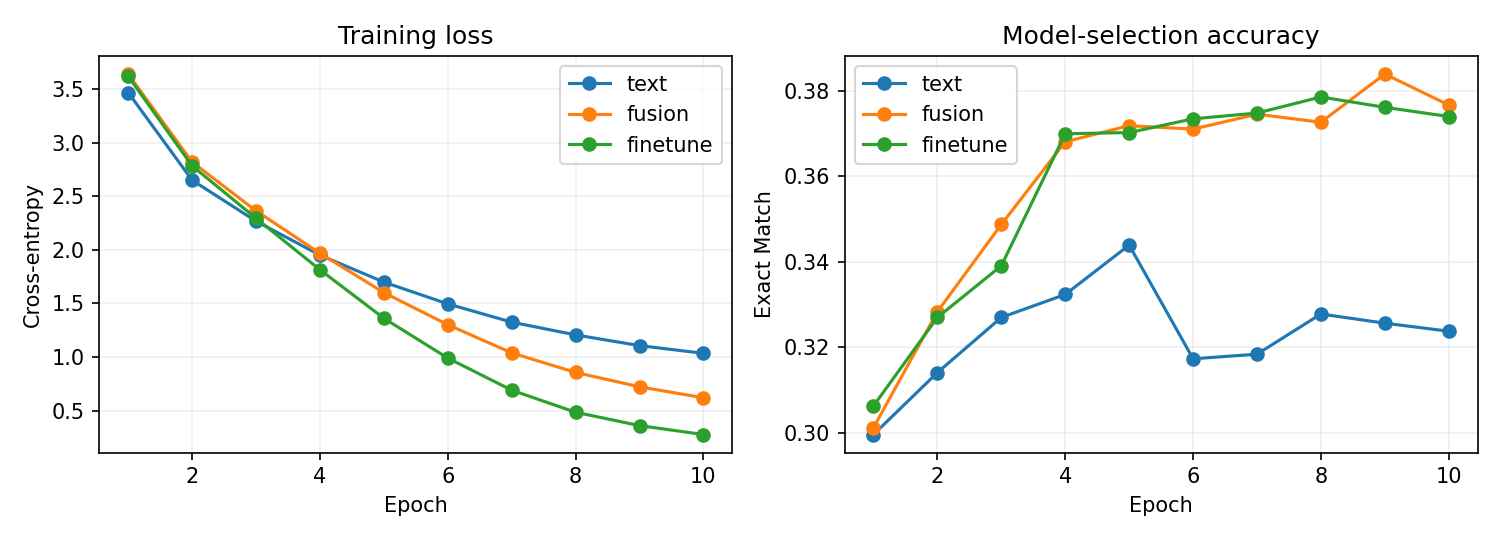

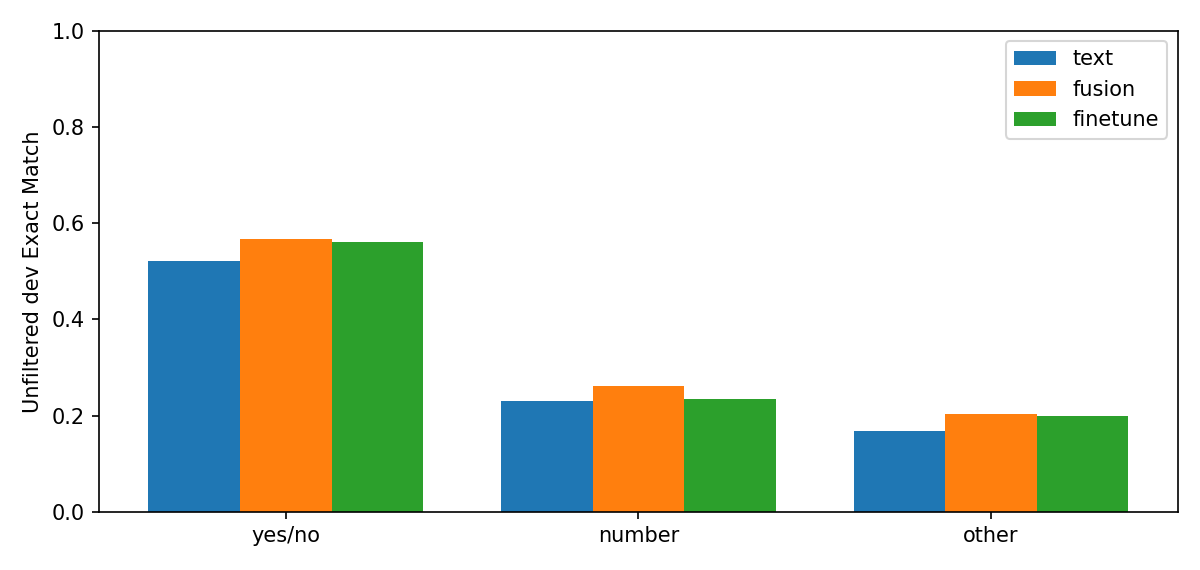

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for mode in ("text", "fusion", "finetune"):
    axes[0].plot([r["epoch"] for r in histories[mode]],
                 [r["train_loss"] for r in histories[mode]], marker="o", label=mode)
    axes[1].plot([r["epoch"] for r in histories[mode]],
                 [r["selection_accuracy"] for r in histories[mode]], marker="o", label=mode)
for axis in axes:
    axis.grid(alpha=0.2)
    axis.legend()
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy", title="Training loss")
axes[1].set(xlabel="Epoch", ylabel="Exact Match", title="Model-selection accuracy")
fig.tight_layout()
fig.savefig(RESULTS / "three_way_training_curves.png", dpi=150)
plt.close(fig)

fig, axis = plt.subplots(figsize=(8, 3.8))
types = list(by_type)
positions = list(range(len(types)))
width = 0.26
for offset, mode in enumerate(("text", "fusion", "finetune")):
    axis.bar([x + (offset - 1) * width for x in positions],
             [by_type[t][mode]["exact_match"] for t in types], width, label=mode)
axis.set_xticks(positions, types)
axis.set_ylim(0, 1)
axis.set_ylabel("Unfiltered dev Exact Match")
axis.legend()
fig.tight_layout()
fig.savefig(RESULTS / "three_way_by_type.png", dpi=150)
plt.close(fig)

summary = {
    "task": "VQA v2 Top-1000 answer classification, three aligned training groups",
    "design": ("All three groups train a freshly initialised classification head for the same "
               "number of epochs with identical data, seed, optimizer and hyperparameters. "
               "The only differences are whether image features enter the head and whether the "
               "last visual block of CLIP is unfrozen."),
    "seed": SEED, "epochs": EPOCHS, "batch_size": BATCH_SIZE,
    "head_lr": HEAD_LR, "backbone_lr": BACKBONE_LR,
    "selected_model": selected,
    "train_images": len(train_ids), "train_questions": len(train_rows),
    "dev_images": len(dev_ids), "dev_filtered_questions": len(dev_rows),
    "dev_all_questions": len(all_dev), "dev_vocab_coverage": coverage,
    "train_observed_answers": len(seen_train_labels),
    "dev_unseen_class_questions": unseen_dev_questions,
    "selection_images": len(selection_ids), "calibration_images": len(calibration_ids),
    "best_epoch": best_epochs,
    "scores": evaluation, "by_answer_type": by_type,
    "temperatures": temperatures, "majority_answer": majority_answer,
    "head_trainable_params": sum(p.numel() for p in heads[selected].parameters()),
    "finetune_backbone_params": sum(
        p.numel() for n, p in clip_model.visual.named_parameters()
        if n.startswith("transformer.resblocks.11") or n.startswith("ln_post") or n == "proj"),
    "device": (torch.cuda.get_device_name(0) if DEVICE == "cuda"
               else ("Apple MPS" if DEVICE == "mps" else "CPU")),
    "python": platform.python_version(), "torch": torch.__version__,
    "metric_note": ("VQA-style 10-annotator agreement with short-answer normalization; "
                    "official Test-Dev score requires EvalAI."),
}
(RESULTS / "three_way_summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
torch.save({"state_dict": heads[selected].state_dict(), "vocabulary": vocabulary,
            "selected_model": selected, "temperature": temperatures[selected]},
           RESULTS / "three_way_head.pt")

probabilities = {mode: (logits / temperatures[mode]).softmax(1)
                 for mode, logits in all_logits.items()}
prediction_rows = []
for index, row in enumerate(all_dev):
    record = {key: row[key] for key in ("question_id", "image_id", "image",
                                         "question", "answer", "answer_type", "label_id")}
    record["models"] = {}
    for mode in ("text", "fusion", "finetune"):
        probability, predicted_id = probabilities[mode][index].max(0)
        record["models"][mode] = {
            "answer": vocabulary[int(predicted_id)],
            "confidence": round(float(probability), 4),
            "exact_match": int(predicted_id) == row["label_id"],
            "vqa_style": round(vqa_style_score(vocabulary[int(predicted_id)],
                                               row["human_answers"]), 4),
        }
    prediction_rows.append(record)
(RESULTS / "three_way_predictions.json").write_text(
    json.dumps(prediction_rows, ensure_ascii=False, indent=2), encoding="utf-8")
print("Saved three-way summary, development predictions, plots and head checkpoint")
print("Selected model:", selected)
for mode in ("text", "fusion", "finetune"):
    print(f"  {mode:9s} filtered_dev EM={evaluation[mode]['filtered_dev']['exact_match']*100:.1f}% "
          f"VQA-style={evaluation[mode]['filtered_dev']['vqa_style']*100:.1f}%")


## 运行日志（Apple MPS，12,400 条 QA）

```text
device: mps
note: Apple MPS backend; results are not comparable with the CUDA run on another machine.
Train: 12400 QA / 2000 images
Dev: 4960 in-vocab QA / 5547 total QA / 800 images; coverage=89.4%
Model selection: 3719 QA; calibration: 1241 QA
Training labels observed: 829/1000; in-vocabulary dev QA with unseen training label: 81
Unfiltered dev answer types: {'other': 2692, 'yes/no': 2062, 'number': 793}
Feature cache: top1000_features_675687a840fc.pt
text      epoch=1 loss=3.4659 selection_acc=0.300
text      epoch=2 loss=2.6495 selection_acc=0.314
text      epoch=3 loss=2.2671 selection_acc=0.327
text      epoch=4 loss=1.9512 selection_acc=0.332
text      epoch=5 loss=1.6993 selection_acc=0.344
text      epoch=6 loss=1.4966 selection_acc=0.317
text      epoch=7 loss=1.3262 selection_acc=0.318
text      epoch=8 loss=1.2072 selection_acc=0.328
text      epoch=9 loss=1.1075 selection_acc=0.326
text      epoch=10 loss=1.0357 selection_acc=0.324
fusion    epoch=1 loss=3.6383 selection_acc=0.301
fusion    epoch=2 loss=2.8181 selection_acc=0.328
fusion    epoch=3 loss=2.3637 selection_acc=0.349
fusion    epoch=4 loss=1.9682 selection_acc=0.368
fusion    epoch=5 loss=1.6018 selection_acc=0.372
fusion    epoch=6 loss=1.3022 selection_acc=0.371
fusion    epoch=7 loss=1.0397 selection_acc=0.375
fusion    epoch=8 loss=0.8576 selection_acc=0.373
fusion    epoch=9 loss=0.7238 selection_acc=0.384
fusion    epoch=10 loss=0.6216 selection_acc=0.377
finetune  epoch=1 loss=3.6178 selection_acc=0.306 332s
finetune  epoch=2 loss=2.7825 selection_acc=0.327 335s
finetune  epoch=3 loss=2.2945 selection_acc=0.339 332s
finetune  epoch=4 loss=1.8145 selection_acc=0.370 332s
finetune  epoch=5 loss=1.3626 selection_acc=0.370 337s
finetune  epoch=6 loss=0.9912 selection_acc=0.373 514s
finetune  epoch=7 loss=0.6925 selection_acc=0.375 379s
finetune  epoch=8 loss=0.4867 selection_acc=0.379 334s
finetune  epoch=9 loss=0.3622 selection_acc=0.376 359s
finetune  epoch=10 loss=0.2787 selection_acc=0.374 439s
Selected fusion using selection accuracy; text=0.344, fusion=0.384, finetune=0.379
text filtered_dev {'exact_match': 0.3445564516129032, 'vqa_style': 0.4231854838709653, 'questions': 4960} unfiltered_dev {'exact_match': 0.30809446547683433, 'vqa_style': 0.38150351541373484, 'questions': 5547} temperature 1.257
fusion filtered_dev {'exact_match': 0.3879032258064516, 'vqa_style': 0.4660080645161277, 'questions': 4960} unfiltered_dev {'exact_match': 0.34685415539931497, 'vqa_style': 0.4200648999459154, 'questions': 5547} temperature 1.617
finetune filtered_dev {'exact_match': 0.3792338709677419, 'vqa_style': 0.45725806451612777, 'questions': 4960} unfiltered_dev {'exact_match': 0.33910221741481883, 'vqa_style': 0.41229493419866464, 'questions': 5547} temperature 1.773
Selected model by answer type: {'yes/no': {'text': {'exact_match': 0.521823472356935, 'vqa_style': 0.6520368574199785, 'questions': 2062}, 'fusion': {'exact_match': 0.5674102812803103, 'vqa_style': 0.6890397672162922, 'questions': 2062}, 'finetune': {'exact_match': 0.561105722599418, 'vqa_style': 0.6863724539282228, 'questions': 2062}}, 'number': {'text': {'exact_match': 0.23076923076923078, 'vqa_style': 0.28108448928121066, 'questions': 793}, 'fusion': {'exact_match': 0.2610340479192938, 'vqa_style': 0.3191677175283735, 'questions': 793}, 'finetune': {'exact_match': 0.23455233291298866, 'vqa_style': 0.29457755359394716, 'questions': 793}}, 'other': {'text': {'exact_match': 0.16716196136701336, 'vqa_style': 0.20386329866270475, 'questions': 2692}, 'fusion': {'exact_match': 0.20319465081723626, 'vqa_style': 0.24375928677563152, 'questions': 2692}, 'finetune': {'exact_match': 0.199851411589896, 'vqa_style': 0.237035661218425, 'questions': 2692}}}
Saved three-way summary, development predictions, plots and head checkpoint
Selected model: fusion
  text      filtered_dev EM=34.5% VQA-style=42.3%
  fusion    filtered_dev EM=38.8% VQA-style=46.6%
  finetune  filtered_dev EM=37.9% VQA-style=45.7%
```
